<a href="https://colab.research.google.com/github/mfauzanadhimh/Image_Segmentation_and_Morphological_Process/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assigment 3 PCD

Nama: Muhammad Fauzan Adhim Husnuddin
NIM: 25/557151/PA/23405

In [ ]:
from PIL import Image
from google.colab import drive
import numpy as np
import pandas as pd


drive.mount('/content/drive')

gauva='/content/drive/MyDrive/pcd/assigment3/gauva.JPG'
bael='/content/drive/MyDrive/pcd/assigment3/bael.JPG'
arjun='/content/drive/MyDrive/pcd/assigment3/arjun.JPG'




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Image Aqcuisition

In [ ]:
img_gauva = Image.open(gauva).convert("RGB")
img_bael = Image.open(bael).convert("RGB")
img_arjun = Image.open(arjun).convert("RGB")

gauva_array = np.array(img_gauva)
bael_array = np.array(img_bael)
arjun_array = np.array(img_arjun)



Region Growing

In [ ]:
from collections import deque

def region_growing(image, seed, treshold):
  img = Image.open(image).convert("RGB")
  img_array = np.array(img)

  height, width, channels = img_array.shape
  mask = np.zeros((height, width), dtype=np.uint8)

  sr, sc = seed
  seed_color = img_array[sr, sc]

  visited = np.zeros((height, width), dtype=bool)

  mask[sr, sc] = 1
  visited[sr, sc] = True

  neighbors = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1)
  ]

  queue = deque([(sr, sc)])

  while queue:
    r, c = queue.popleft()

    for dr, dc in neighbors:
      nr = r + dr
      nc = c + dc

      if 0 <= nr < height and 0 <= nc < width and not visited[nr, nc]:
        visited[nr, nc] = True
        neighbor_color = img_array[nr, nc]

        distance_squared = 0

        for channel in range(3):
          distance = int(neighbor_color[channel]) - int(seed_color[channel])
          distance_squared += distance ** 2

        if distance_squared < treshold ** 2:
          mask[nr, nc] = 1
          queue.append((nr, nc))

  return mask


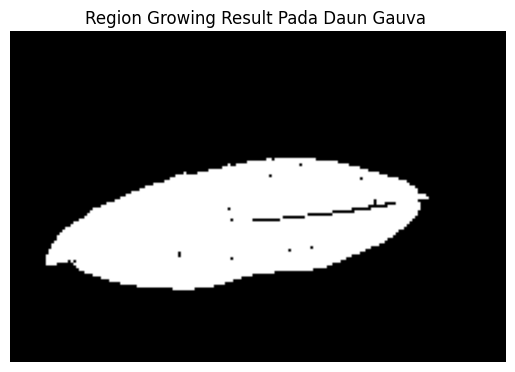

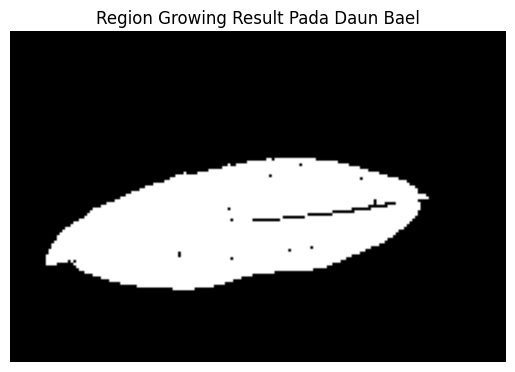

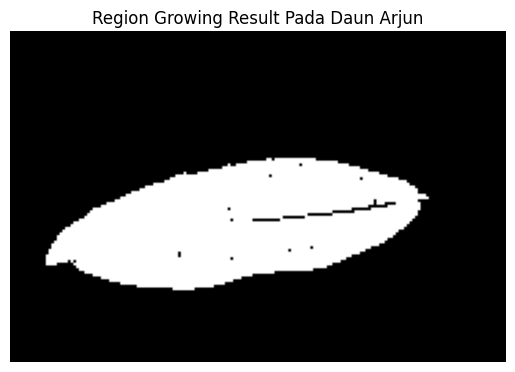

In [ ]:
import matplotlib.pyplot as plt


mask_gauva = region_growing(gauva, (60, 100), 70)
plt.imshow(mask, cmap='gray', vmin=0, vmax=1)
plt.title("Region Growing Result Pada Daun Gauva ")
plt.axis('off')
plt.show()

mask_bael = region_growing(bael, (60, 100), 100)
plt.imshow(mask, cmap='gray', vmin=0, vmax=1)
plt.title("Region Growing Result Pada Daun Bael")
plt.axis('off')
plt.show()

mask_arjun = region_growing(arjun, (60, 100), 50)
plt.imshow(mask, cmap='gray', vmin=0, vmax=1)
plt.title("Region Growing Result Pada Daun Arjun")
plt.axis('off')
plt.show()

Erosion

In [ ]:
def erosion(mask):
  height, width = mask.shape

  output = np.zeros((height, width), dtype=np.uint8)

  neighbors = [
    (-1, -1),
    (-1, 0),
    (-1, 1),
    (1, 0),
    (0, 0),
    (0, -1),
    (1, -1),
    (0, 1),
    (1,1)
  ]

  for r in range(height):
    for c in range(width):

      all_one = True

      for dr, dc in neighbors:
        nr = r + dr
        nc = c + dc

        if not (0 <= nr < height and 0 <= nc < width):
          all_one = False
          break

        if mask[nr, nc] == 0:
          all_one = False
          break

      if all_one:
          output[r, c] = 1

  return output

Dilatation

In [ ]:
def dilatation(mask):
  height, width = mask.shape

  output = np.zeros((height, width), dtype=np.uint8)

  neighbors = [
    (-1, -1),
    (-1, 0),
    (-1, 1),
    (1, 0),
    (0, 0),
    (0, -1),
    (1, -1),
    (0, 1),
    (1,1)
  ]

  for r in range(height):
    for c in range(width):

      any_one = False

      for dr, dc in neighbors:
        nr = r + dr
        nc = c + dc

        if not (0 <= nr < height and 0 <= nc < width):
          continue

        if mask[nr, nc] == 1:
          any_one = True
          break

      if any_one:
          output[r, c] = 1

  return output

Opening

In [ ]:
def opening(mask):
  eroded = erosion(mask)
  opened = dilatation(eroded)
  return opened

Closing

In [ ]:
def closing(mask):
  dilated = dilatation(mask)
  closed = erosion(dilated)
  return closed

Morphological Processing

In [ ]:
datasets = {
    "Guava": {"image": gauva_array, "mask": mask_gauva},
    "Bael": {"image": bael_array, "mask": mask_bael},
    "Arjun": {"image": arjun_array, "mask": mask_arjun},
}

results = {}
for leaf_name, data in datasets.items():
    original = data["image"]
    region_mask = data["mask"]

    if original.shape[:2] != region_mask.shape:
        raise ValueError(f"Dimensi gambar dan mask {leaf_name} tidak cocok")

    results[leaf_name] = {
        "Original": original,
        "Region Growing": region_mask,
        "Erosion": erosion(region_mask),
        "Dilation": dilatation(region_mask),
        "Opening": opening(region_mask),
        "Closing": closing(region_mask),
    }

    print(f"{leaf_name}: seluruh operasi selesai, ukuran mask {region_mask.shape}")

Guava: seluruh operasi selesai, ukuran mask (120, 180)
Bael: seluruh operasi selesai, ukuran mask (120, 180)
Arjun: seluruh operasi selesai, ukuran mask (120, 180)


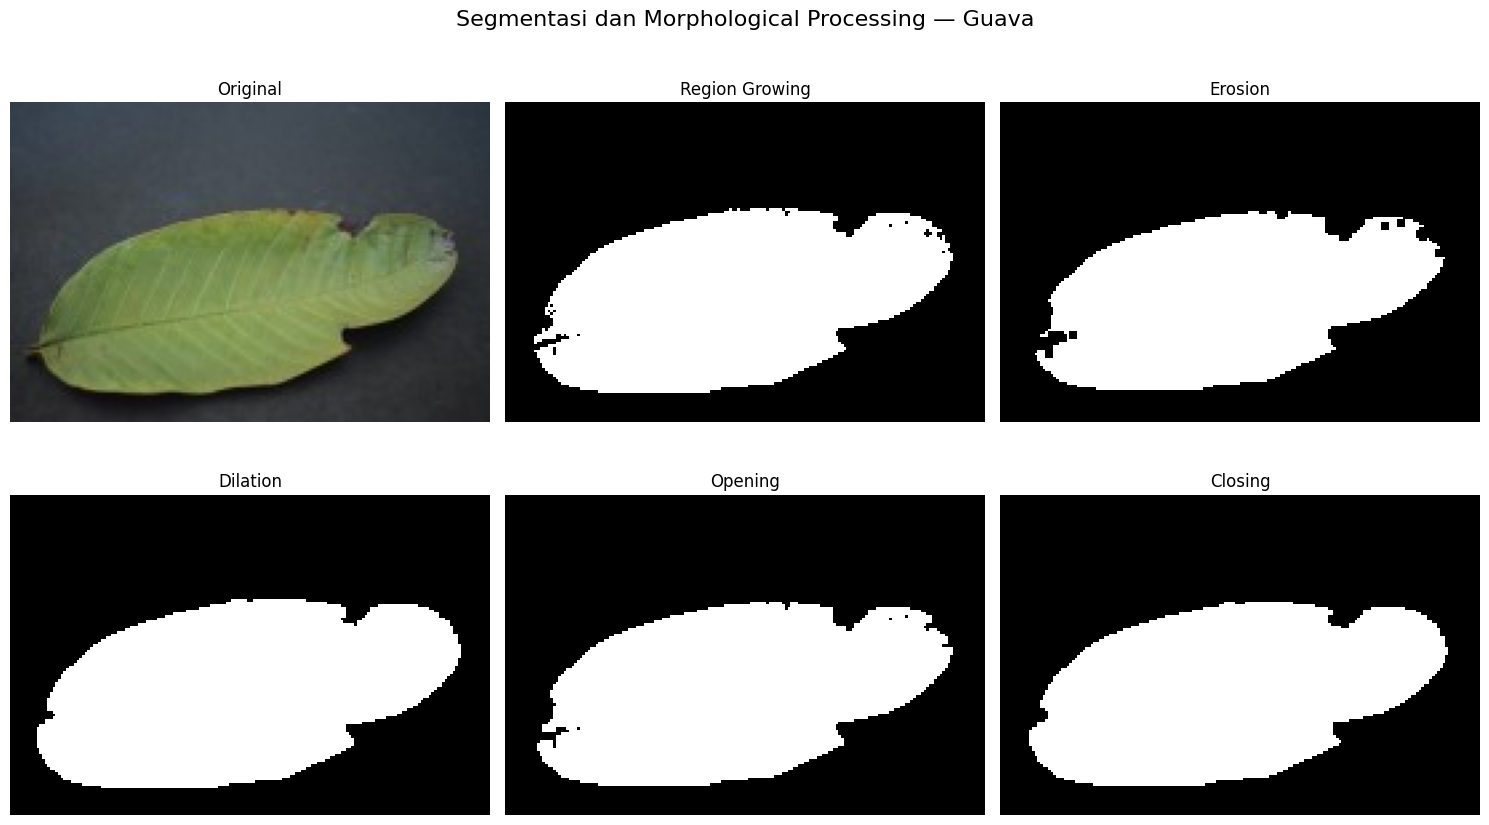

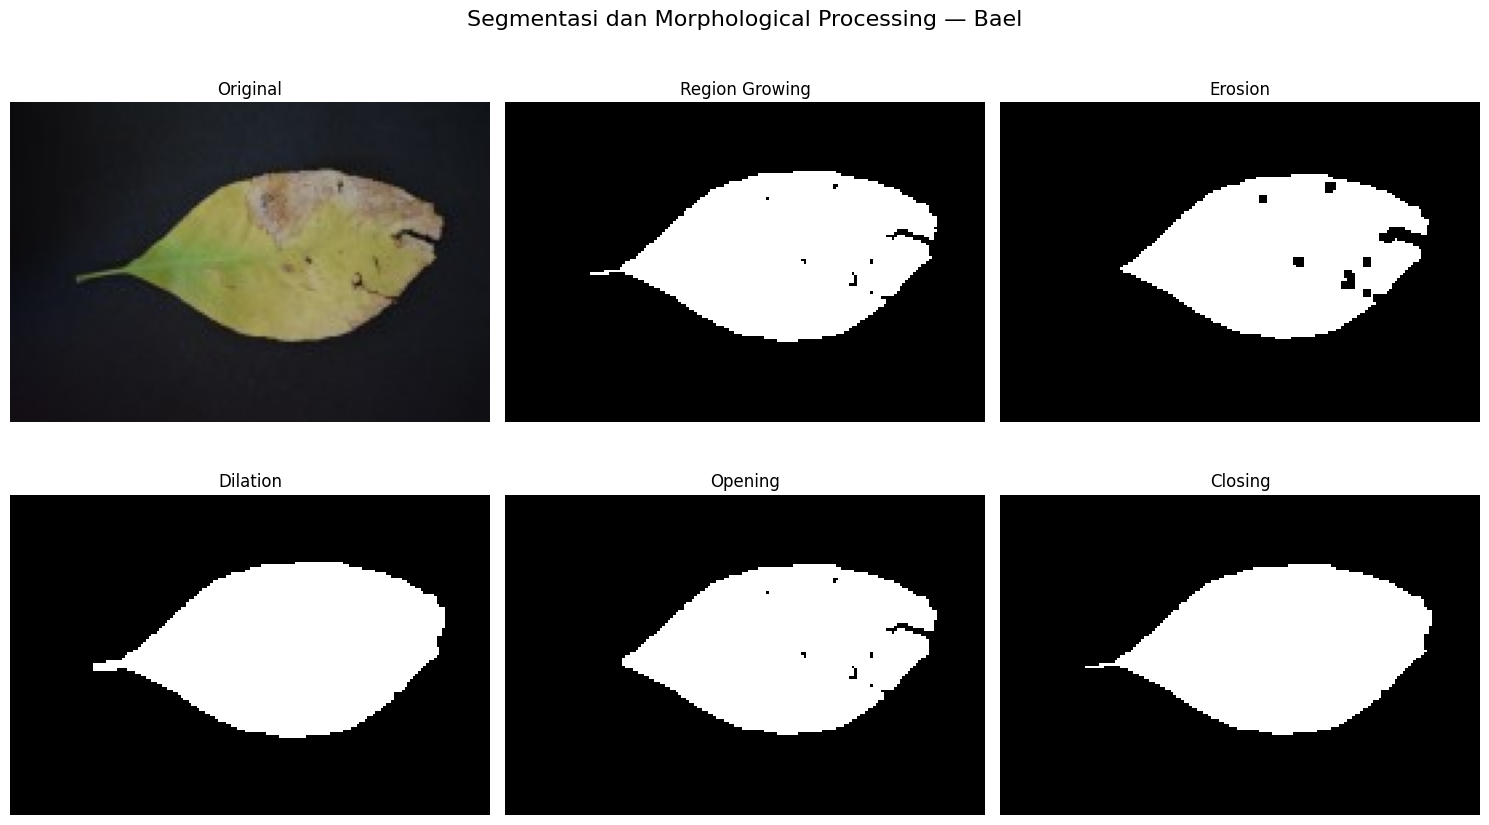

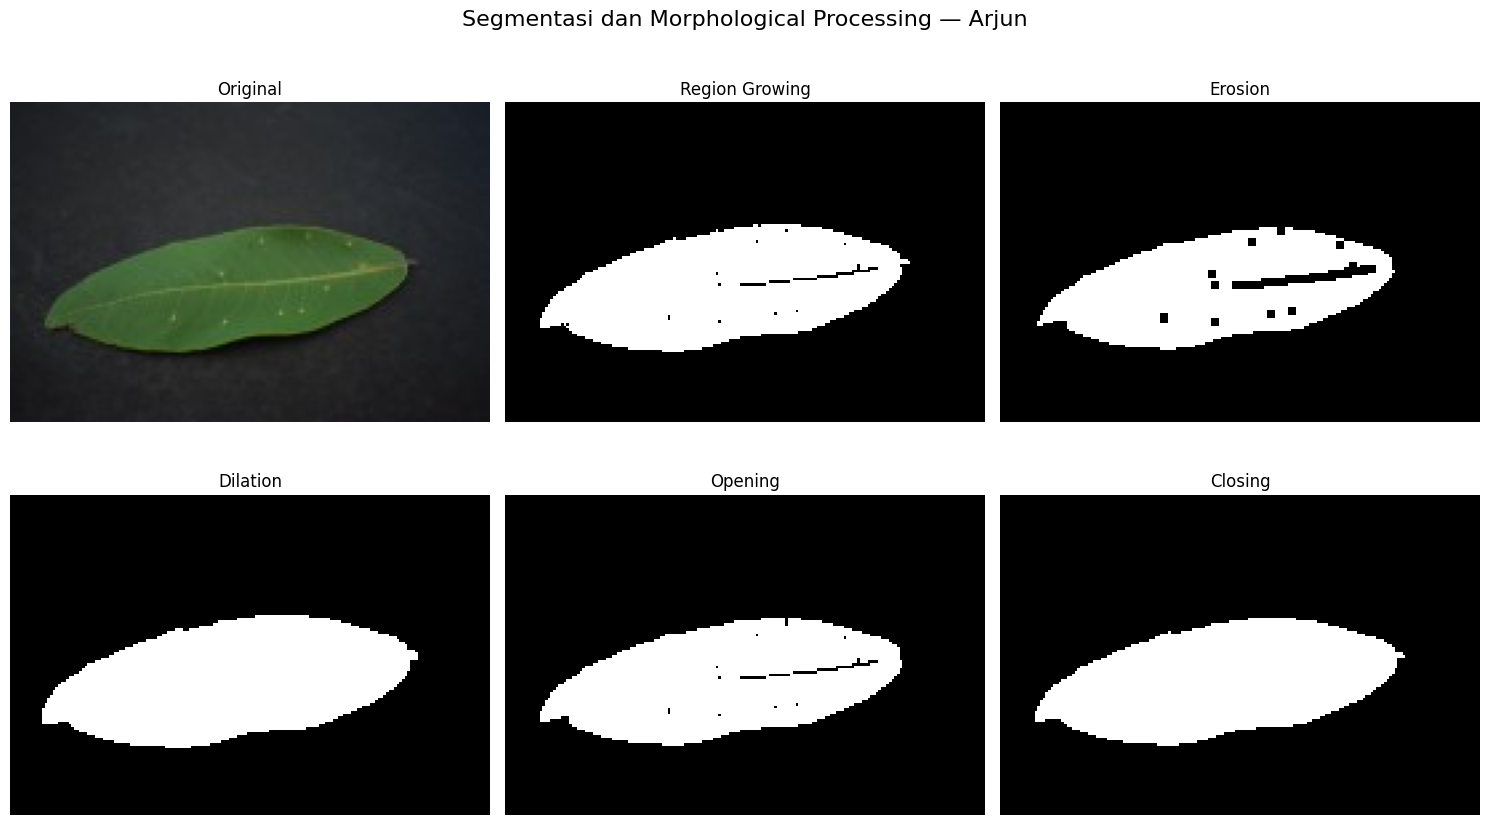

In [ ]:
order = ["Original", "Region Growing", "Erosion", "Dilation", "Opening", "Closing"]

for leaf_name, outputs in results.items():
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    fig.suptitle(f"Segmentasi dan Morphological Processing — {leaf_name}", fontsize=16)

    for ax, operation in zip(axes.flat, order):
        image_to_show = outputs[operation]

        if operation == "Original":
            ax.imshow(image_to_show)
        else:
            ax.imshow(image_to_show, cmap="gray", vmin=0, vmax=1,
                      interpolation="nearest")

        ax.set_title(operation)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

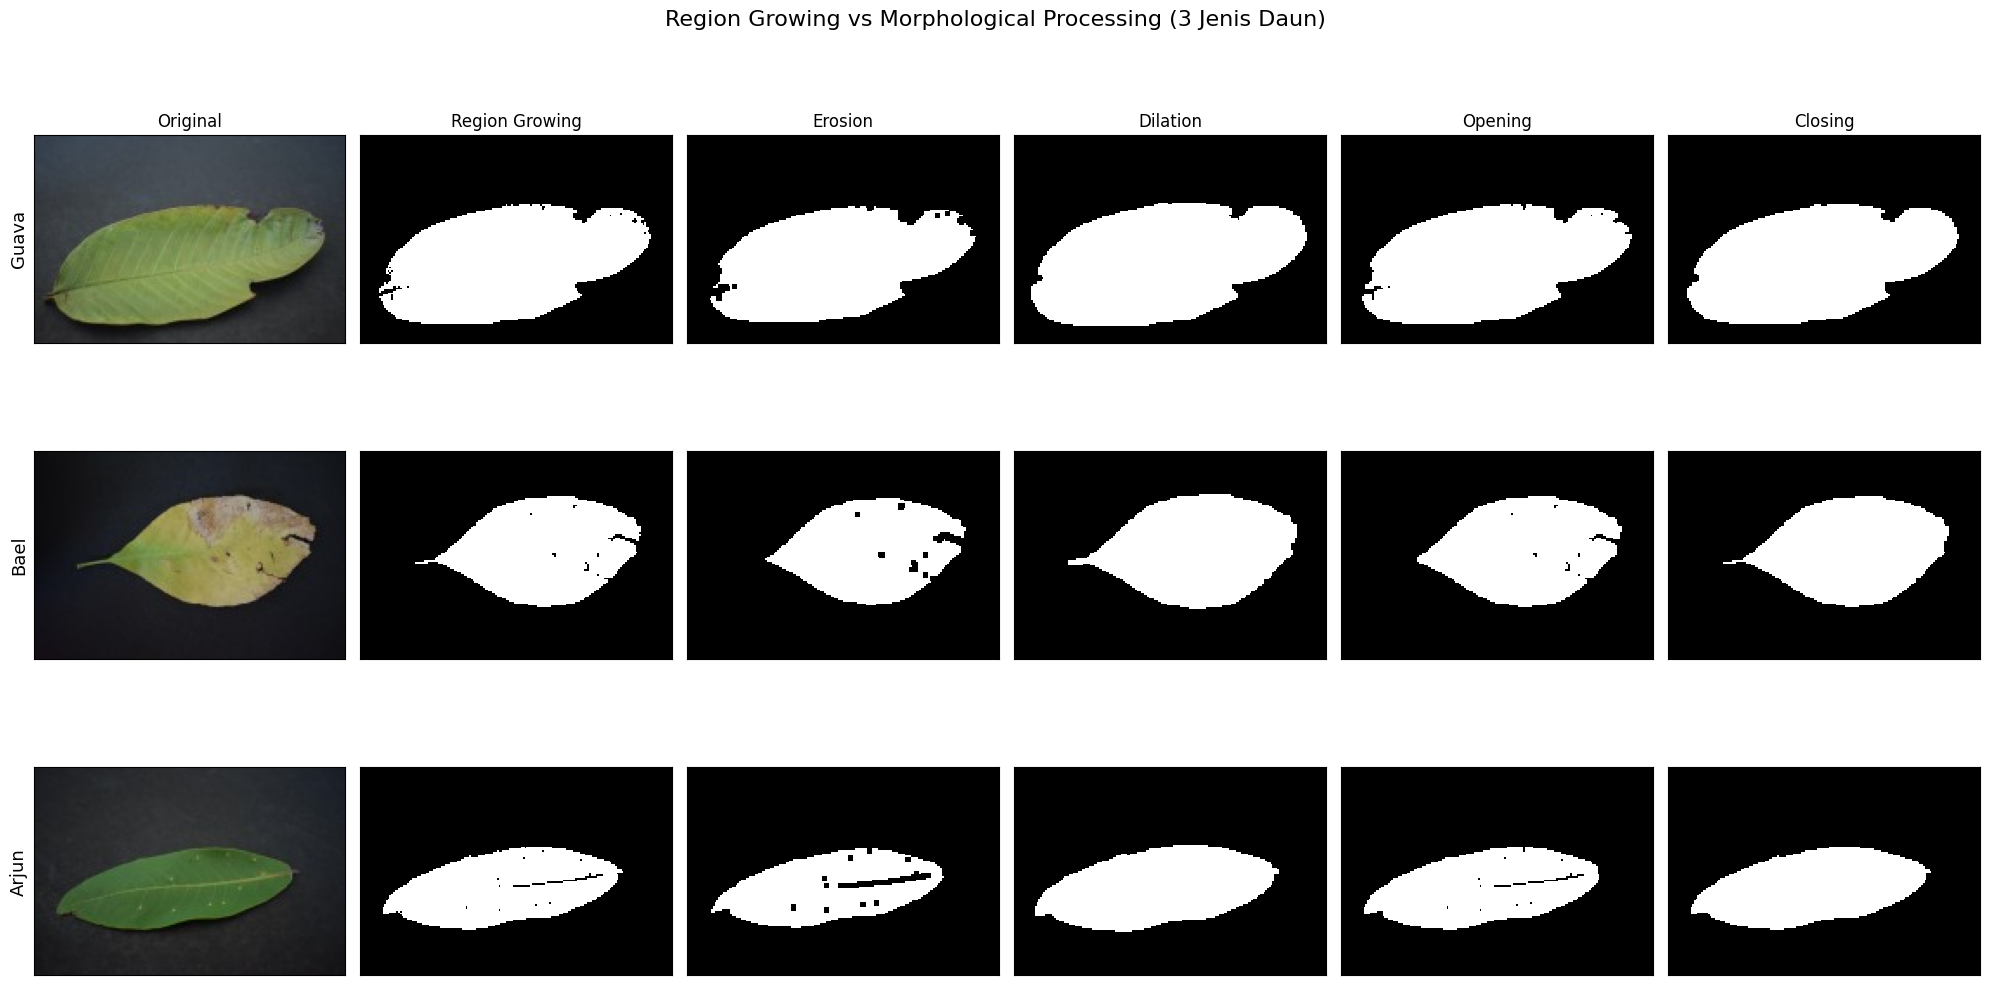

In [ ]:
fig, axes = plt.subplots(len(results), len(order), figsize=(20, 11))

for i, (leaf_name, outputs) in enumerate(results.items()):
    for j, operation in enumerate(order):
        ax = axes[i, j]

        if operation == "Original":
            ax.imshow(outputs[operation])
        else:
            ax.imshow(outputs[operation], cmap="gray", vmin=0, vmax=1,
                      interpolation="nearest")

        if i == 0:
            ax.set_title(operation, fontsize=12)
        if j == 0:
            ax.set_ylabel(leaf_name, rotation=90, fontsize=13)
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle("Region Growing vs Morphological Processing (3 Jenis Daun)",
             fontsize=16)
plt.tight_layout()
plt.show()